# 01 · Exploratory data analysis

**Lights Out: Predicting Storm-Driven Power Outages and Recovery Across U.S. Counties**

First step of our Option A analysis. We load the three tables we will model on, look at what is
missing and why, and describe the two targets:

- `peak_share_out`: share of a county's customers out at the peak. A **major outage** is
  `peak_share_out > 0.10` (classification target).
- `hours_to_90pct_restored`: hours until 90% of customers are back (regression target).

Then we look at outages by storm type, by state and by year.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path('..') / 'data'
pd.set_option('display.max_columns', 40)
plt.rcParams['figure.figsize'] = (9, 4)

## 1. Load the data

In [2]:
storms = pd.read_csv(DATA / 'storms.csv')
county = pd.read_csv(DATA / 'county_summary.csv', low_memory=False)
utility = pd.read_csv(DATA / 'utility_by_county.csv', low_memory=False)

for name, df in [('storms', storms), ('county_summary', county), ('utility_by_county', utility)]:
    print(f'{name:18s} {df.shape[0]:>7,} rows  {df.shape[1]:>3} columns')

storms                 672 rows   14 columns
county_summary      51,493 rows   52 columns
utility_by_county   11,686 rows   31 columns


In [3]:
storms.head()

,event_id,name,kind,landfall,landfall_time_utc,first_impact_date,states,source,night_light_unit,night_light_reason,product,outage_reason,window_note,also_known_as
0,AL012026,Arthur,tropical,2026-06-15,NaN,NaN,LA MS,Catalog landfall date (storms.csv source NHC-A...,county,NaN,VJ146A2,no_published_year,NaN,NaN
1,AL022019,Barry,tropical,2019-07-13,15:00,2019-07-11,LA,"NHC HURDAT2 best track, U.S. landfall record 1...",county,NaN,VNP46A2,NaN,NaN,NaN
2,AL022024,Beryl,tropical,2024-07-08,08:40,NaN,TX,"NHC HURDAT2 best track, U.S. landfall record 0...",county,NaN,VNP46A2,NaN,NaN,NaN
3,AL042024,Debby,tropical,2024-08-05,11:00,2024-08-03,FL GA NC NY PA SC VT,"NHC HURDAT2 best track, U.S. landfall record 1...",county,NaN,VNP46A2,NaN,NaN,NaN
4,AL052019,Dorian,tropical,2019-09-06,12:30,2019-08-28,FL GA NC PR SC VI,"NHC HURDAT2 best track, U.S. landfall record 1...",county,NaN,VNP46A2,NaN,NaN,NaN


In [4]:
utility.head()

,event_id,geoid,county,state,declared,available,reason,source,peak_customers_out,peak_reason,peak_customers_out_raw,flagged_readings,peak_share_out,peak_share_reason,customer_hours_out,hours_to_50pct_restored,hours_to_50pct_reason,hours_to_90pct_restored,hours_to_90pct_reason,hours_under_1pct_customers,hours_under_1pct_reason,coverage_gap,customers_total,customers_reason,estimate_exceeded_in_other_storm,outage_window_end_day,outage_window_end_reason,window_note,customers_source,customer_hours_reason,reporting_drop
0,AL022019,22001,Acadia,LA,True,True,ok,utility_records,2515.0,NaN,2515.0,0.0,0.0820,NaN,44913.0,1.50,NaN,18.25,NaN,9.75,NaN,True,30685.5,NaN,False,45,window,NaN,eia861-fips-v2_year_2019,reporting_drop,False
1,AL022019,22003,Allen,LA,True,True,ok,utility_records,696.0,NaN,696.0,0.0,0.0602,NaN,13248.5,12.00,NaN,12.00,NaN,12.00,NaN,False,11568.5,NaN,True,45,window,NaN,eia861-fips-v2_year_2019,NaN,False
2,AL022019,22005,Ascension,LA,True,True,ok,utility_records,8501.0,NaN,8501.0,1.0,0.1491,NaN,154975.4,NaN,reporting_drop,NaN,reporting_drop,NaN,reporting_drop,True,57023.6,NaN,False,45,window,NaN,eia861-fips-v2_year_2019,reporting_drop,True
3,AL022019,22007,Assumption,LA,True,True,ok,utility_records,7598.0,NaN,12744.0,1.0,0.6009,NaN,330285.5,30.50,NaN,52.00,NaN,75.50,NaN,True,12644.4,NaN,False,45,window,NaN,eia861-fips-v2_year_2019,NaN,False
4,AL022019,22009,Avoyelles,LA,True,True,ok,utility_records,6368.0,NaN,6368.0,0.0,0.2951,NaN,126608.5,6.25,NaN,12.00,NaN,39.00,NaN,True,21576.7,NaN,False,45,window,NaN,eia861-fips-v2_year_2019,NaN,False


`storms.csv` has one row per storm. `event_id` is either a NOAA storm id (`AL022019` = 2nd Atlantic
storm of 2019, `EP…` = eastern Pacific) or a FEMA declaration number (`DR-4586`).
`utility_by_county.csv` has one row per storm and county, and holds the two targets.

In [5]:
storms['id_type'] = storms['event_id'].str.extract(r'^(AL|EP|DR|EM)')[0].fillna('other')
print(storms['id_type'].value_counts())
print()
print(storms['kind'].value_counts())

id_type
DR    636
AL     35
EP      1
Name: count, dtype: int64

kind
severe_storm           347
flood                  186
tropical                36
tornado                 24
severe_ice_storm        21
winter_storm            21
snowstorm               20
typhoon                  8
straight-line_winds      6
coastal_storm            3
Name: count, dtype: int64


We add storm type and year to each county row. The year comes from the landfall date, or from the
first impact date when there is no landfall.

In [6]:
storms['date'] = pd.to_datetime(storms['landfall'].fillna(storms['first_impact_date']), errors='coerce')
storms['year'] = storms['date'].dt.year

df = utility.merge(storms[['event_id', 'name', 'kind', 'year']], on='event_id', how='left')
print('rows without a matching storm:', df['kind'].isna().sum())
df[['event_id', 'name', 'kind', 'year', 'state', 'county', 'peak_share_out', 'hours_to_90pct_restored']].head()

rows without a matching storm: 0


,event_id,name,kind,year,state,county,peak_share_out,hours_to_90pct_restored
0,AL022019,Barry,tropical,2019,LA,Acadia,0.0820,18.25
1,AL022019,Barry,tropical,2019,LA,Allen,0.0602,12.00
2,AL022019,Barry,tropical,2019,LA,Ascension,0.1491,NaN
3,AL022019,Barry,tropical,2019,LA,Assumption,0.6009,52.00
4,AL022019,Barry,tropical,2019,LA,Avoyelles,0.2951,12.00


## 2. Missing values and their reasons

In this dataset **an empty cell is never a zero**. Each column that can be empty has a `*_reason`
column that says why. We count missing values first, then read the reasons.

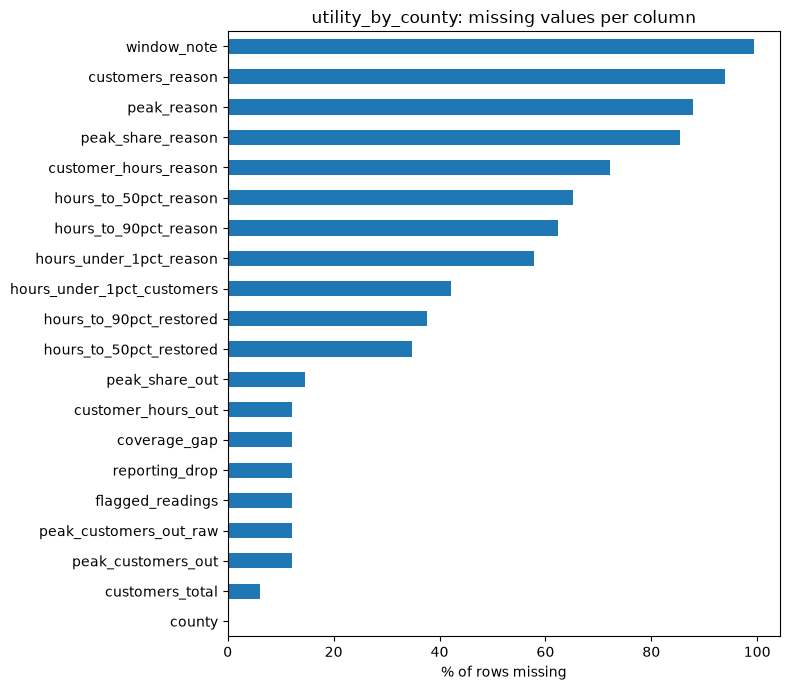

In [7]:
missing = utility.isna().mean().sort_values(ascending=False)
missing = missing[missing > 0]
ax = (missing * 100).plot.barh(figsize=(8, 7))
ax.set_xlabel('% of rows missing')
ax.set_title('utility_by_county: missing values per column')
ax.invert_yaxis()
plt.tight_layout(); plt.show()

In [8]:
reason_cols = [c for c in utility.columns if c.endswith('reason')]
for c in reason_cols:
    print(f'--- {c}')
    print(utility[c].value_counts(dropna=False).head(8).to_string(), end='\n\n')

--- reason
reason
ok                   10260
no_utility_record     1048
no_rows_in_window      378

--- peak_reason
peak_reason
NaN                  10260
no_utility_record     1426

--- peak_share_reason
peak_share_reason
NaN                             9989
no_utility_record               1426
peak_above_customer_estimate     246
no_customers_total                25

--- hours_to_50pct_reason
hours_to_50pct_reason
NaN                       7616
reporting_drop            1636
no_utility_record         1426
not_restored_in_window     962
no_customers_out            45
peak_mismatch                1

--- hours_to_90pct_reason
hours_to_90pct_reason
NaN                       7297
reporting_drop            1752
no_utility_record         1426
not_restored_in_window    1165
no_customers_out            45
peak_mismatch                1

--- hours_under_1pct_reason
hours_under_1pct_reason
NaN                             6768
reporting_drop                  1625
no_utility_record               

What the reasons tell us:

- `reason` / `peak_reason` = `no_utility_record` or `no_rows_in_window`: EAGLE-I has no outage data
  for that county in the storm window. Both targets are empty and these rows cannot be used.
- `peak_share_reason` = `peak_above_customer_estimate`: more customers were reported out than the
  estimated customer count of the county (`customers_total` is an estimate from EIA-861 and Census
  housing units). The share is left empty instead of being above 100%.
- `hours_to_90pct_reason`:
  - `reporting_drop`: the utility stopped reporting during the storm, so the restore time is unknown;
  - `not_restored_in_window`: 90% was not reached before the end of the observation window. These
    are the **longest** outages, so dropping them biases the regression target downwards. This is
    right-censoring, which we will need to handle (or at least discuss) in the regression step;
  - `no_customers_out`: nobody lost power, so there is nothing to restore.

The same logic applies to the night-light columns of `county_summary.csv`:

In [9]:
nl_reason_cols = ['reason', 'days_to_50_reason', 'days_to_normal_reason', 'window_end_reason']
for c in nl_reason_cols:
    print(f'--- {c}')
    print(county[c].value_counts(dropna=False).head(8).to_string(), end='\n\n')
print('status:'); print(county['status'].value_counts(dropna=False).to_string())

--- reason
reason
county_not_declared              29495
ok                               10260
no_utility_record_before_2014     7980
no_published_year                 2334
no_utility_record                 1046
no_rows_in_window                  378

--- days_to_50_reason
days_to_50_reason
no_outage_measured             15688
not_observed_cloud             15103
not_measurable_low_signal      14078
never_below_50                  2576
NaN                             2261
not_observed_too_few_nights     1745
not_back_to_50_in_window          42

--- days_to_normal_reason
days_to_normal_reason
no_outage_measured              15688
not_observed_cloud              15103
not_measurable_low_signal       14078
NaN                              4723
not_observed_too_few_nights      1745
not_back_to_normal_in_window      156

--- window_end_reason
window_end_reason
window                39056
data_end               5804
next_storm:DR-4586      254
next_storm:DR-4598      144
next_storm:DR-4570

In [10]:
print('Storms without night light :', storms['night_light_reason'].notna().sum())
print(storms['night_light_reason'].value_counts().to_string(), end='\n\n')
print('Storms without an outage run:', storms['outage_reason'].notna().sum())
print(storms['outage_reason'].value_counts().to_string())

Storms without night light : 14
night_light_reason
territory_not_in_county_boundaries    11
before_nasa_record                     3

Storms without an outage run: 195
outage_reason
no_utility_record_before_2014    117
no_county_outage_record           41
no_published_year                 30
territory_not_in_eaglei            7


## 3. Target 1: `peak_share_out` (major outage = more than 10% of customers out)

In [11]:
share = df['peak_share_out'].dropna()
print(share.describe())
df['major_outage'] = (df['peak_share_out'] > 0.10).where(df['peak_share_out'].notna())
print()
print(df['major_outage'].value_counts(dropna=False).rename({1.0: 'major (>10%)', 0.0: 'not major', float('nan'): 'unknown'}))
print(f"\nShare of major outages among known rows: {df['major_outage'].mean():.1%}")

count    9989.000000
mean        0.190851
std         0.222084
min         0.000000
25%         0.033900
50%         0.098100
75%         0.271500
max         0.999300
Name: peak_share_out, dtype: float64

major_outage
not major       5039
major (>10%)    4950
NaN             1697
Name: count, dtype: int64

Share of major outages among known rows: 49.6%


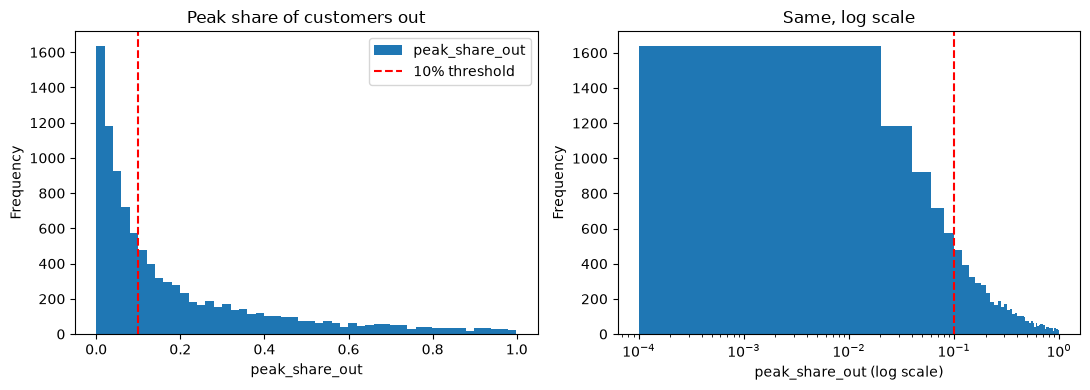

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
share.plot.hist(bins=50, ax=axes[0])
axes[0].axvline(0.10, color='red', ls='--', label='10% threshold')
axes[0].set_xlabel('peak_share_out'); axes[0].set_title('Peak share of customers out'); axes[0].legend()
share.clip(lower=1e-4).plot.hist(bins=50, ax=axes[1], logx=True)
axes[1].set_xscale('log'); axes[1].axvline(0.10, color='red', ls='--')
axes[1].set_xlabel('peak_share_out (log scale)'); axes[1].set_title('Same, log scale')
plt.tight_layout(); plt.show()

The share is very skewed: most counties lose a few percent of customers, a long tail loses almost
all of them. The 10% threshold splits the known rows into two classes of similar size, so the
classification task is not strongly imbalanced.

## 4. Target 2: `hours_to_90pct_restored`

In [13]:
hours = df['hours_to_90pct_restored'].dropna()
print(hours.describe())
print('\nmedian:', hours.median(), 'hours')

count    7297.000000
mean       63.077466
std       100.995167
min         0.500000
25%        11.000000
50%        30.250000
75%        72.000000
max      1009.500000
Name: hours_to_90pct_restored, dtype: float64

median: 30.25 hours


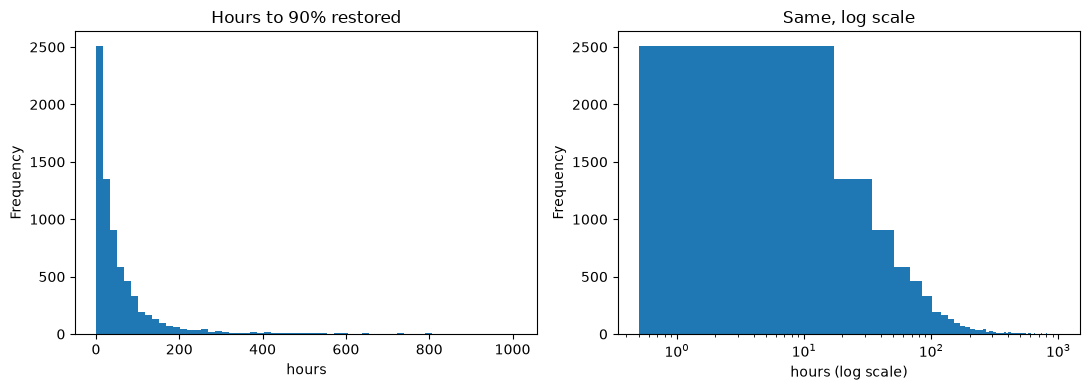

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
hours.plot.hist(bins=60, ax=axes[0])
axes[0].set_xlabel('hours'); axes[0].set_title('Hours to 90% restored')
hours.clip(lower=0.25).plot.hist(bins=60, ax=axes[1])
axes[1].set_xscale('log'); axes[1].set_xlabel('hours (log scale)'); axes[1].set_title('Same, log scale')
plt.tight_layout(); plt.show()

Restoration time also has a long right tail (up to about 1,000 hours). A log transform will
probably help the regression. Remember that the longest outages are partly missing
(`not_restored_in_window`), so the real tail is even longer.

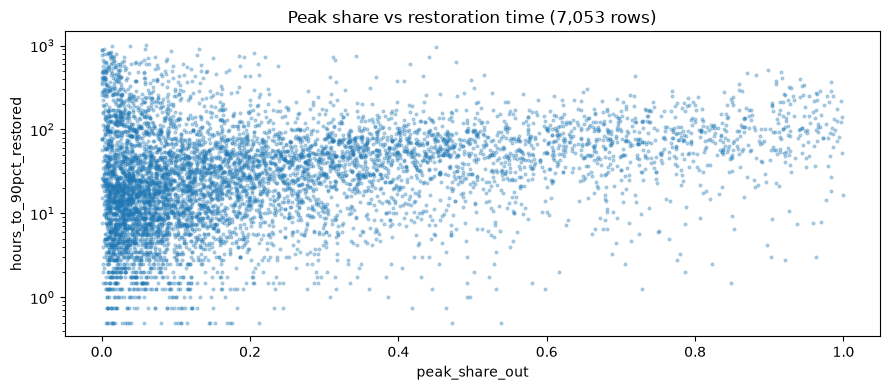

Spearman correlation: 0.292


In [15]:
both = df.dropna(subset=['peak_share_out', 'hours_to_90pct_restored'])
ax = both.plot.scatter(x='peak_share_out', y='hours_to_90pct_restored', s=4, alpha=0.3, logy=True)
ax.set_title(f'Peak share vs restoration time ({len(both):,} rows)')
plt.tight_layout(); plt.show()
# Spearman correlation = Pearson correlation of the ranks
print('Spearman correlation:', round(both['peak_share_out'].rank().corr(both['hours_to_90pct_restored'].rank()), 3))

## 5. Outages by storm type

In [16]:
by_kind = df.groupby('kind').agg(
    storms=('event_id', 'nunique'),
    county_rows=('event_id', 'size'),
    known_share=('peak_share_out', 'count'),
    major_rate=('major_outage', 'mean'),
    median_share=('peak_share_out', 'median'),
    median_hours_90=('hours_to_90pct_restored', 'median'),
).sort_values('county_rows', ascending=False)
by_kind.round(3)

,storms,county_rows,known_share,major_rate,median_share,median_hours_90
kind,,,,,,
tropical,33,4412,3766,0.486989,0.094,30.000
severe_storm,230,3763,3316,0.532871,0.114,29.625
flood,143,2190,1767,0.339559,0.056,24.250
severe_ice_storm,14,671,576,0.8125,0.302,50.500
snowstorm,19,268,215,0.274419,0.036,19.500
tornado,21,201,187,0.545455,0.110,23.250
winter_storm,10,133,124,0.709677,0.203,52.250
straight-line_winds,4,43,33,0.878788,0.332,52.250
coastal_storm,3,5,5,0.6,0.121,11.750


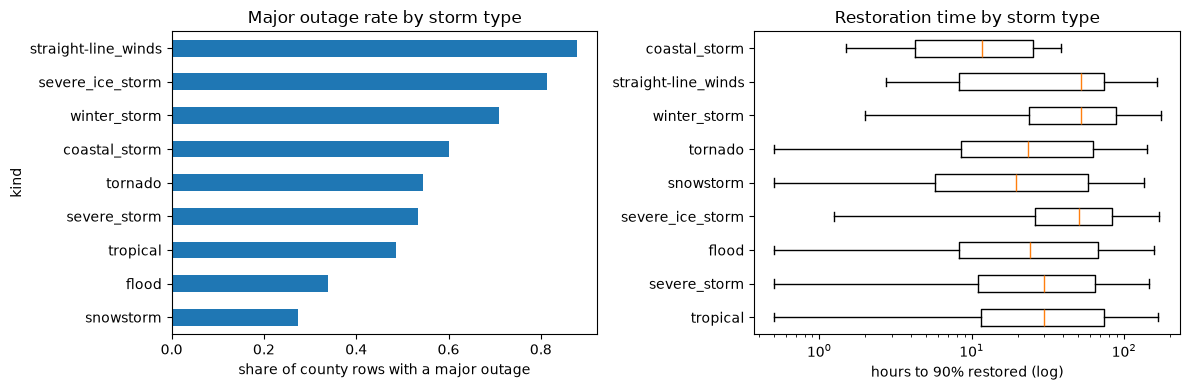

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
by_kind['major_rate'].sort_values().plot.barh(ax=axes[0])
axes[0].set_xlabel('share of county rows with a major outage'); axes[0].set_title('Major outage rate by storm type')
order = by_kind.index.tolist()
data = [df.loc[df['kind'] == k, 'hours_to_90pct_restored'].dropna() for k in order]
axes[1].boxplot(data, orientation='horizontal', showfliers=False)
axes[1].set_yticks(range(1, len(order) + 1), order)
axes[1].set_xscale('log'); axes[1].set_xlabel('hours to 90% restored (log)'); axes[1].set_title('Restoration time by storm type')
plt.tight_layout(); plt.show()

## 6. Outages by state

In [18]:
by_state = df.groupby('state').agg(
    county_rows=('event_id', 'size'),
    storms=('event_id', 'nunique'),
    major_rate=('major_outage', 'mean'),
    median_hours_90=('hours_to_90pct_restored', 'median'),
)
by_state = by_state[by_state['county_rows'] >= 50].sort_values('major_rate', ascending=False)
print(f'{len(by_state)} states with at least 50 county rows')
by_state.head(15).round(3)

36 states with at least 50 county rows


,county_rows,storms,major_rate,median_hours_90
state,,,,
ME,73,12,0.763889,30.000
WV,172,19,0.678788,30.750
GA,674,14,0.658692,44.500
VA,347,10,0.640264,50.250
TX,930,19,0.590966,29.500
ID,56,10,0.5625,73.000
OK,434,17,0.560386,23.875
MS,467,24,0.55711,41.000
AR,305,16,0.555184,31.750


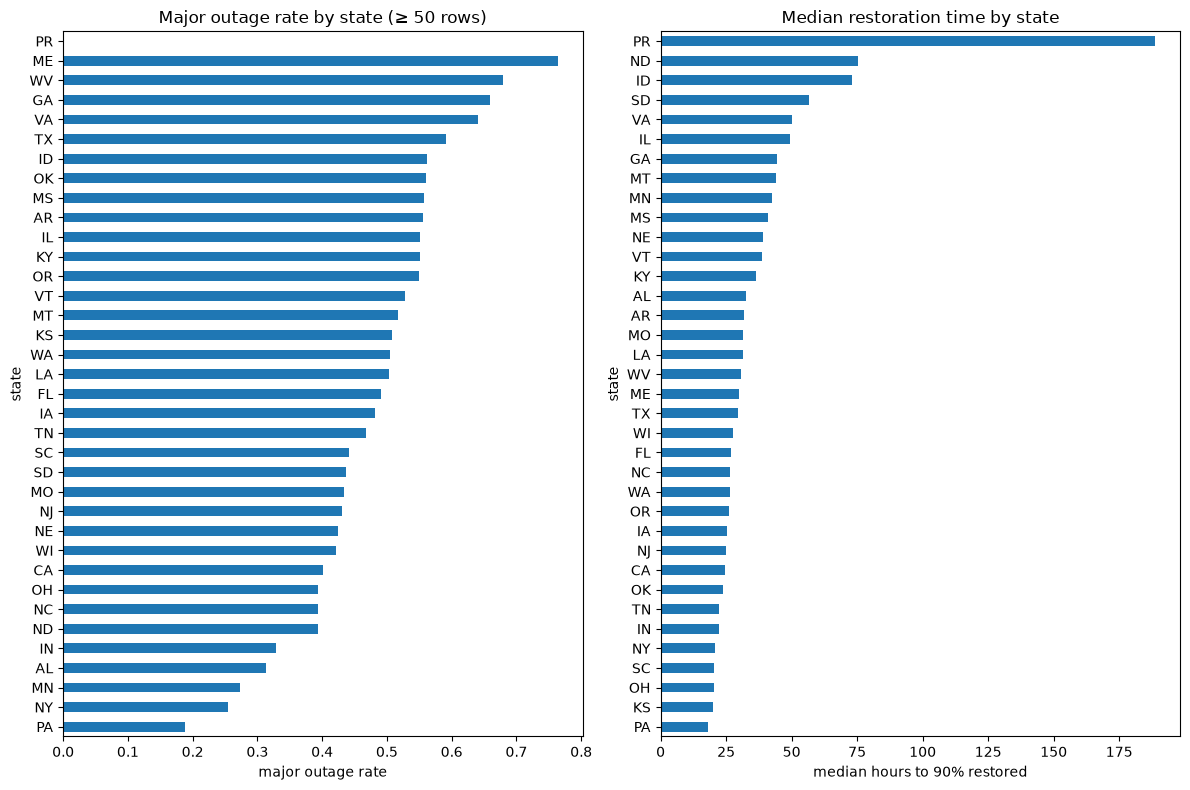

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 8))
by_state['major_rate'].sort_values().plot.barh(ax=axes[0])
axes[0].set_xlabel('major outage rate'); axes[0].set_title('Major outage rate by state (≥ 50 rows)')
by_state['median_hours_90'].sort_values().plot.barh(ax=axes[1])
axes[1].set_xlabel('median hours to 90% restored'); axes[1].set_title('Median restoration time by state')
plt.tight_layout(); plt.show()

## 7. Outages by year

In [20]:
by_year = df.groupby('year').agg(
    storms=('event_id', 'nunique'),
    county_rows=('event_id', 'size'),
    usable_rows=('reason', lambda r: (r == 'ok').sum()),
    major_rate=('major_outage', 'mean'),
    median_hours_90=('hours_to_90pct_restored', 'median'),
)
by_year.index = by_year.index.astype(int)
by_year.round(3)

,storms,county_rows,usable_rows,major_rate,median_hours_90
year,,,,,
2014,3,20,20,0.45,70.75
2015,45,1133,874,0.343318,22.75
2016,30,647,554,0.453039,32.50
2017,47,1156,843,0.512758,41.50
2018,40,900,828,0.43408,28.75
2019,45,1371,1108,0.310909,23.00
2020,36,1280,1165,0.5093,33.25
2021,44,1202,1161,0.620845,34.75
2022,33,722,625,0.525974,26.25


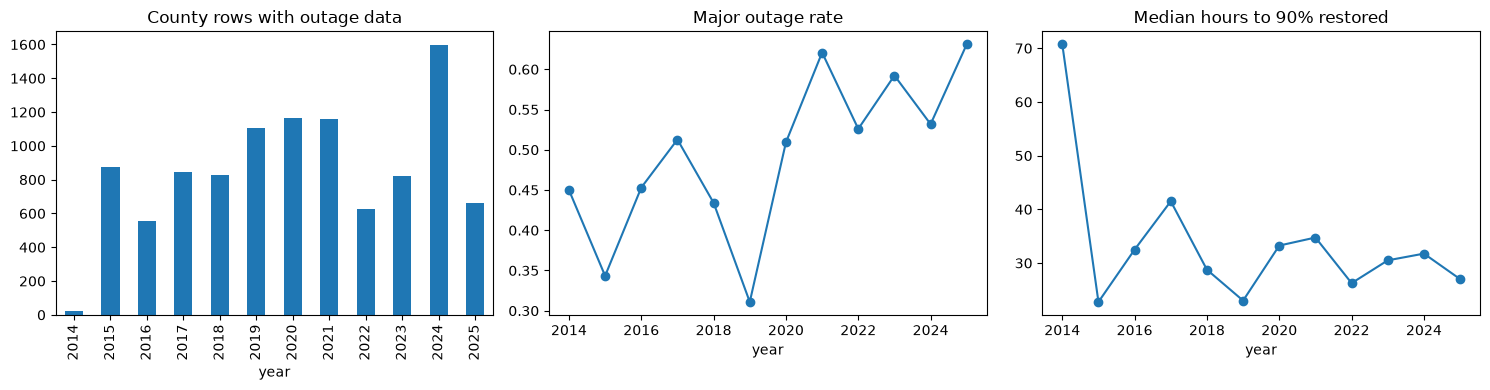

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
by_year['usable_rows'].plot.bar(ax=axes[0]); axes[0].set_title('County rows with outage data')
by_year['major_rate'].plot(marker='o', ax=axes[1]); axes[1].set_title('Major outage rate')
by_year['median_hours_90'].plot(marker='o', ax=axes[2]); axes[2].set_title('Median hours to 90% restored')
for a in axes: a.set_xlabel('year')
plt.tight_layout(); plt.show()

EAGLE-I county records start on 2014-11-01, so there is no outage data before 2014, and early
years have fewer counties covered. Year-to-year changes are driven by a few very large storms
(for example Irma in 2017 and Helene in 2024), so the year is more a proxy for which storms happened than a
trend.

## 8. Summary and next steps

- The modelling table is `utility_by_county.csv` joined to `storms.csv` on `event_id`.
- Rows with `reason != 'ok'` have no outage data and are dropped for modelling.
- **Classification** (`peak_share_out > 0.10`): about 10,000 usable rows, two classes of similar size.
- **Regression** (`hours_to_90pct_restored`): about 7,300 usable rows, long right tail (use a log
  target), and right-censored rows (`not_restored_in_window`) to handle.
- Storm type, state and year all show large differences and are natural first features.
- Only the storms with a NOAA id (`AL…`, `EP…`) can be enriched with HURDAT2 wind speed and pressure.

Next notebook: baseline major-outage classifier.